# Notebook 3 · Question 4: evaluation, comparison and overfitting
Runs `src/evaluate_q4.py`: every model is fit on 2018–2021 and evaluated on the same 244 municipalities of 2022.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
import evaluate_q4
evaluate_q4.main()

Baseline (Dummy)             val macro-F1=0.3662  ROC-AUC=0.5000  PR-AUC=0.4221
Baseline (Repeat last year)  val macro-F1=0.8867  ROC-AUC=0.8872  PR-AUC=0.8094


Logistic Regression          val macro-F1=0.8867  ROC-AUC=0.9284  PR-AUC=0.9218


Random Forest                val macro-F1=0.8784  ROC-AUC=0.9134  PR-AUC=0.8936


MLP                          val macro-F1=0.8789  ROC-AUC=0.9294  PR-AUC=0.9171


Residual Tabular NN          val macro-F1=0.8789  ROC-AUC=0.9268  PR-AUC=0.9195



Provisional champion on validation macro-F1 (ties broken by ROC-AUC): Logistic Regression

Train - validation macro-F1 gap:
                      model  train_macro_f1  val_macro_f1  macro_f1_gap
           Baseline (Dummy)           0.346         0.366        -0.020
Baseline (Repeat last year)           0.865         0.887        -0.022
        Logistic Regression           0.865         0.887        -0.022
              Random Forest           1.000         0.878         0.122
                        MLP           0.869         0.879        -0.010
        Residual Tabular NN           0.868         0.879        -0.011



Saved figures to C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\reports\figures and tables to C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\results


## 4.1 Held-out metrics for every model

In [3]:
q4 = pd.read_csv(RESULTS / "q4_validation_metrics.csv").set_index("model")
q4[[c for c in q4.columns if c.startswith("val_")]]

,val_accuracy,val_macro_f1,val_weighted_f1,val_precision_at_risk,val_recall_at_risk,val_roc_auc,val_pr_auc
model,,,,,,,
Baseline (Dummy),0.578,0.366,0.423,0.000,0.000,0.500,0.422
Baseline (Repeat last year),0.889,0.887,0.889,0.865,0.874,0.887,0.809
Logistic Regression,0.889,0.887,0.889,0.865,0.874,0.928,0.922
Random Forest,0.881,0.878,0.881,0.856,0.864,0.913,0.894
MLP,0.881,0.879,0.881,0.843,0.883,0.929,0.917
Residual Tabular NN,0.881,0.879,0.881,0.843,0.883,0.927,0.920


## 4.2 Classification reports, confusion matrices and ROC curves

In [4]:
print((RESULTS / "q4_classification_reports.txt").read_text())

===== Baseline (Dummy) (validation year 2022, n=244) =====
              precision    recall  f1-score   support

 not_at_risk      0.578     1.000     0.732       141
     at_risk      0.000     0.000     0.000       103

    accuracy                          0.578       244
   macro avg      0.289     0.500     0.366       244
weighted avg      0.334     0.578     0.423       244

===== Baseline (Repeat last year) (validation year 2022, n=244) =====
              precision    recall  f1-score   support

 not_at_risk      0.907     0.901     0.904       141
     at_risk      0.865     0.874     0.870       103

    accuracy                          0.889       244
   macro avg      0.886     0.887     0.887       244
weighted avg      0.890     0.889     0.889       244

===== Logistic Regression (validation year 2022, n=244) =====
              precision    recall  f1-score   support

 not_at_risk      0.907     0.901     0.904       141
     at_risk      0.865     0.874     0.870   

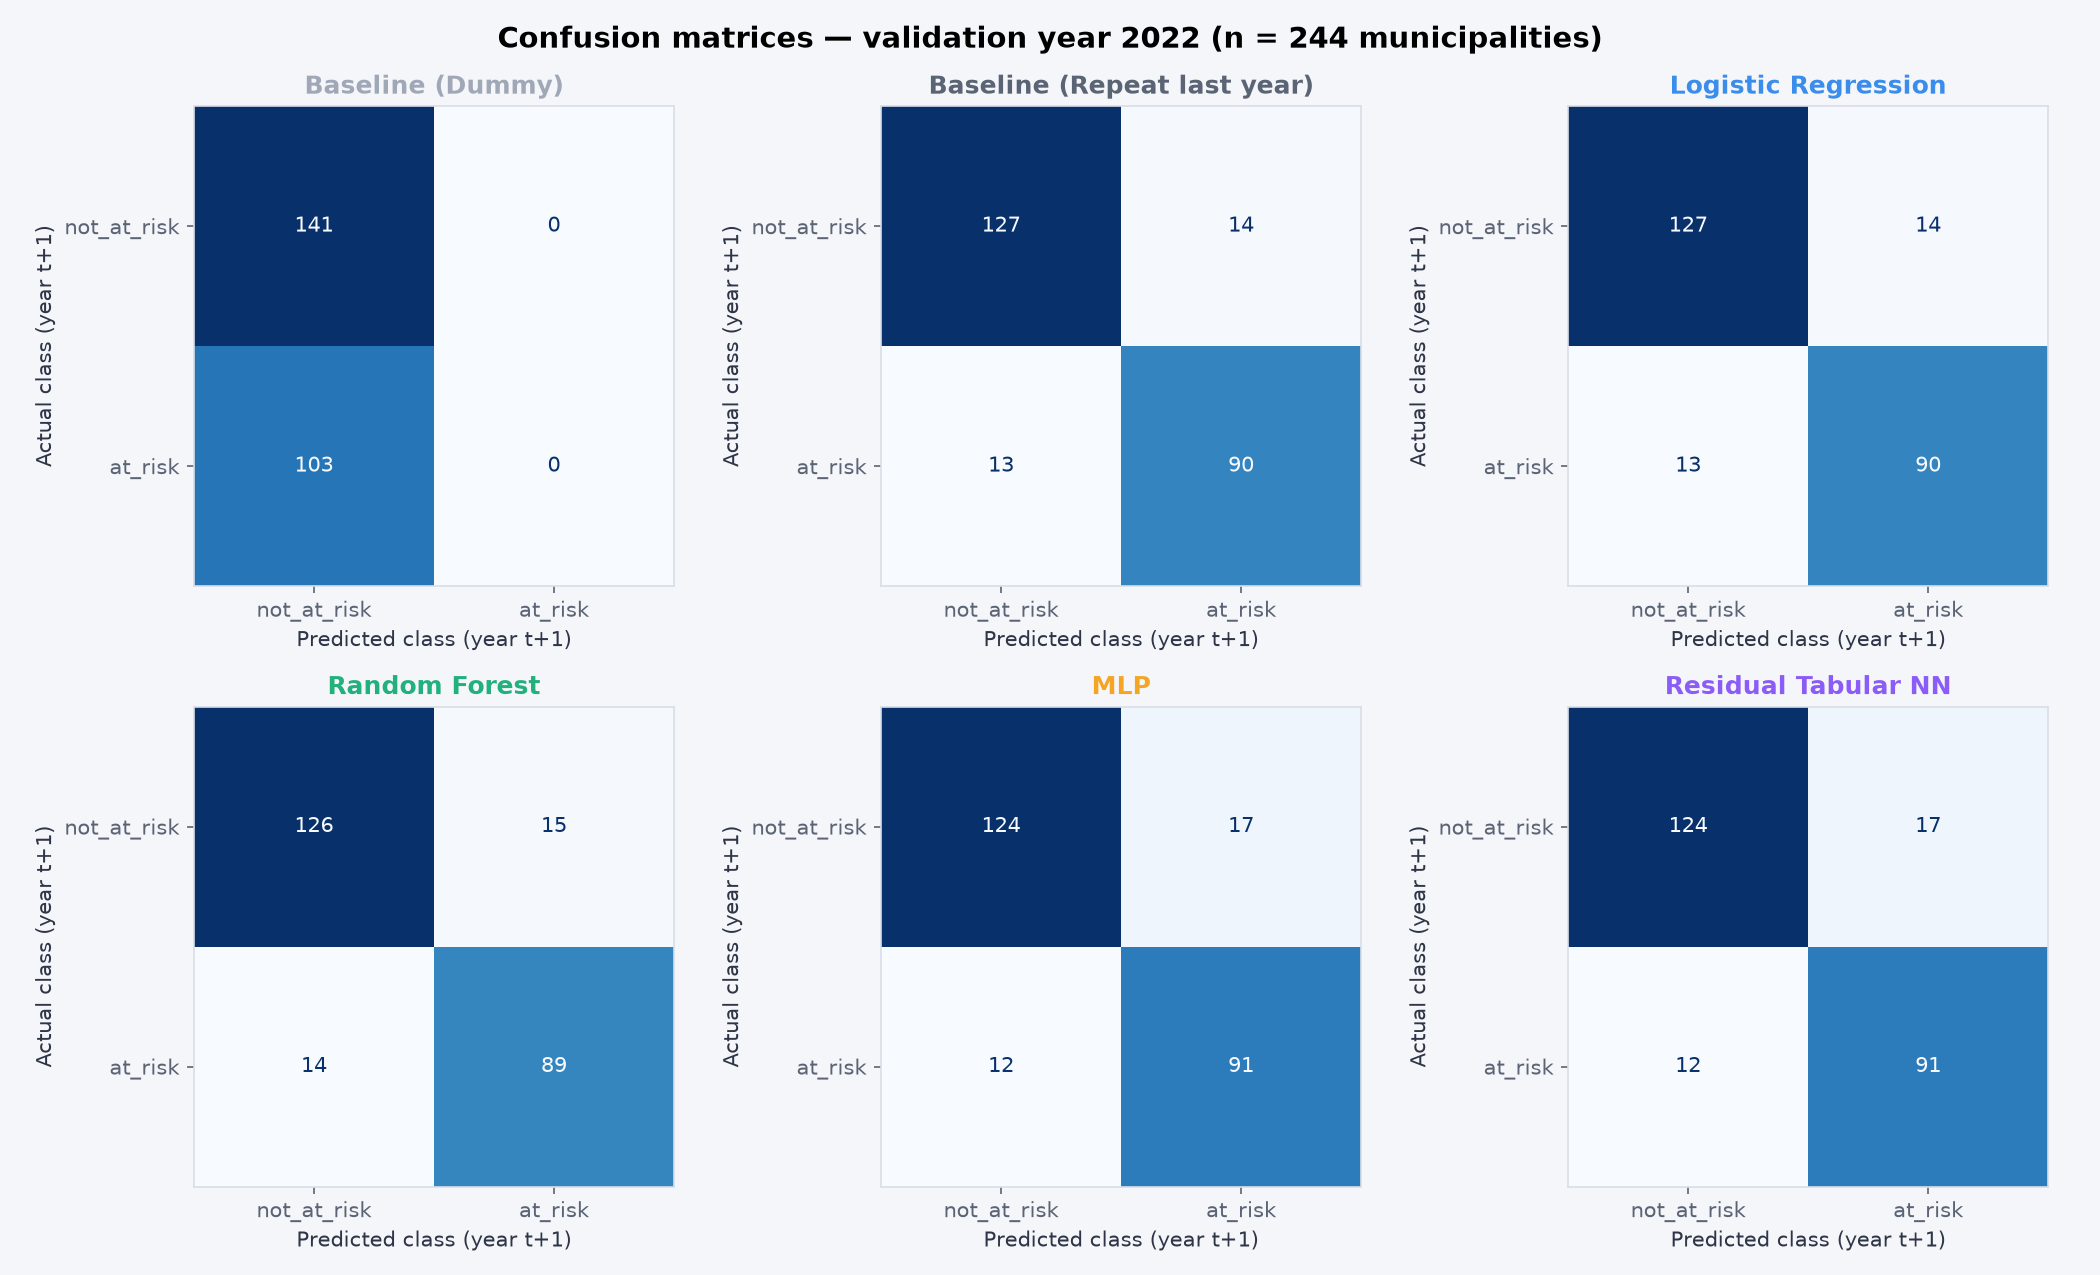

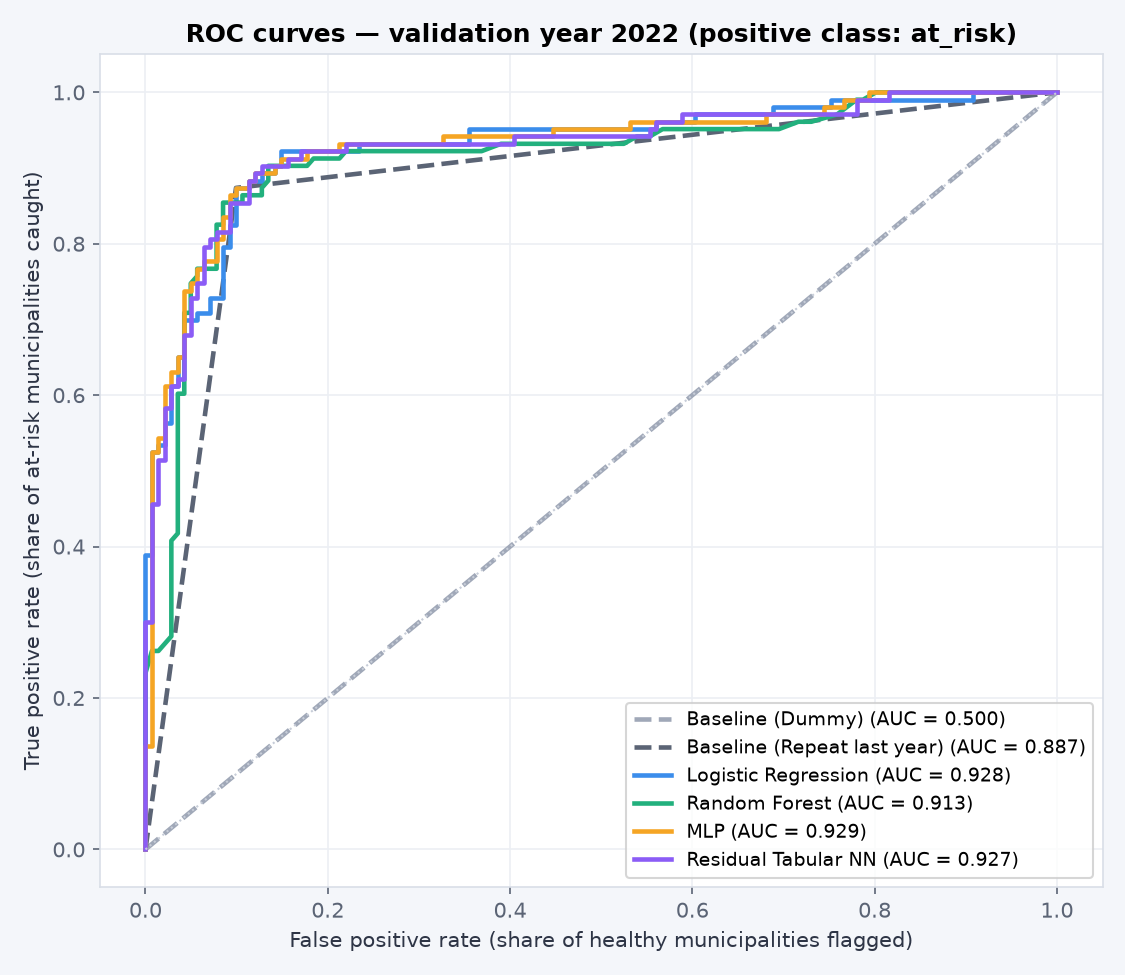

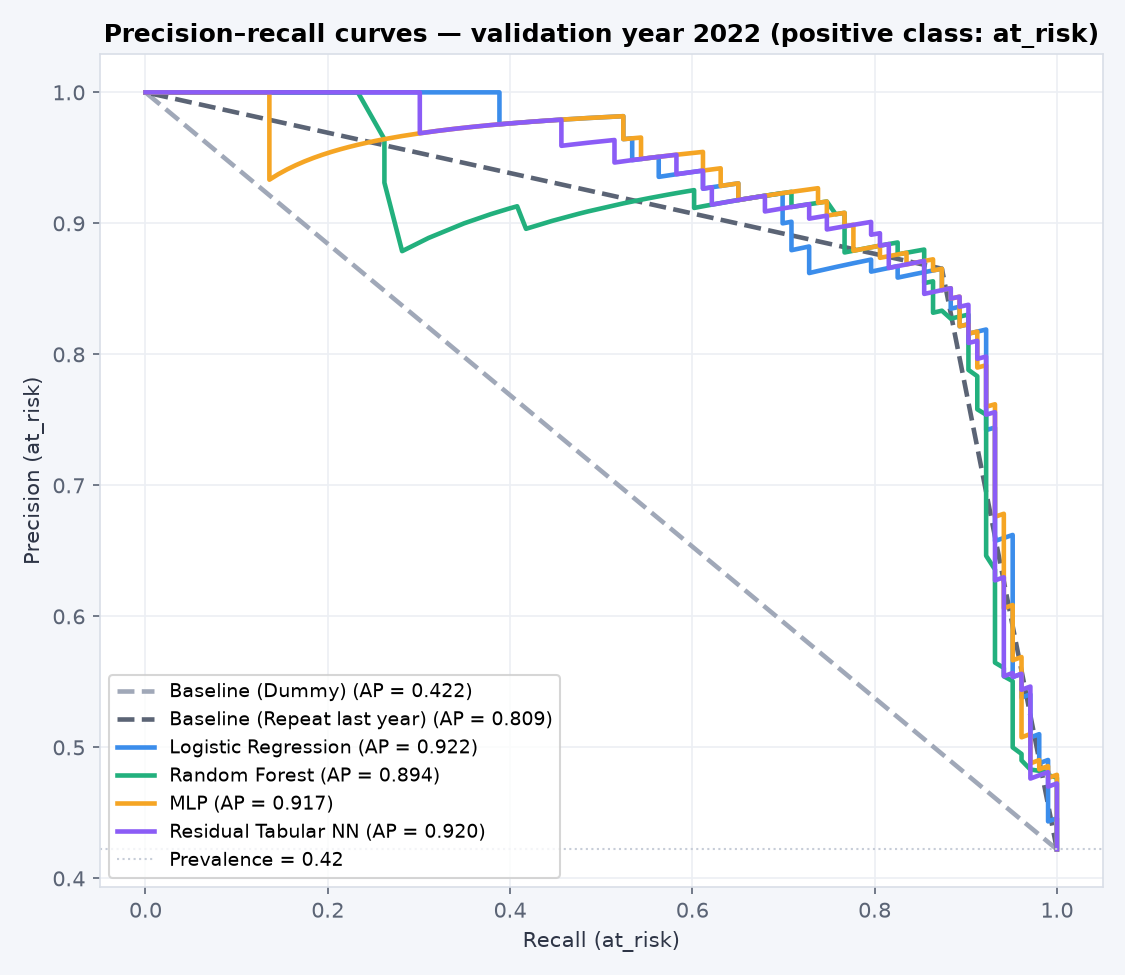

In [5]:
show("q4_confusion_matrices.png", 900)
show("q4_roc_curves.png", 520)
show("q4_pr_curves.png", 520)

## 4.3 Comparison and provisional champion (validation and walk-forward cross-validation)

,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_accuracy_std,fold_2019_macro_f1,fold_2020_macro_f1,fold_2021_macro_f1
model,,,,,,,
Baseline (Dummy),0.331,0.033,0.496,0.075,0.325,0.301,0.366
Baseline (Repeat last year),0.873,0.025,0.874,0.024,0.870,0.899,0.850
Logistic Regression,0.870,0.023,0.871,0.022,0.866,0.895,0.850
Random Forest,0.866,0.020,0.867,0.019,0.866,0.886,0.845
MLP,0.752,0.182,0.762,0.168,0.866,0.542,0.850
Residual Tabular NN,0.742,0.196,0.757,0.174,0.861,0.516,0.850


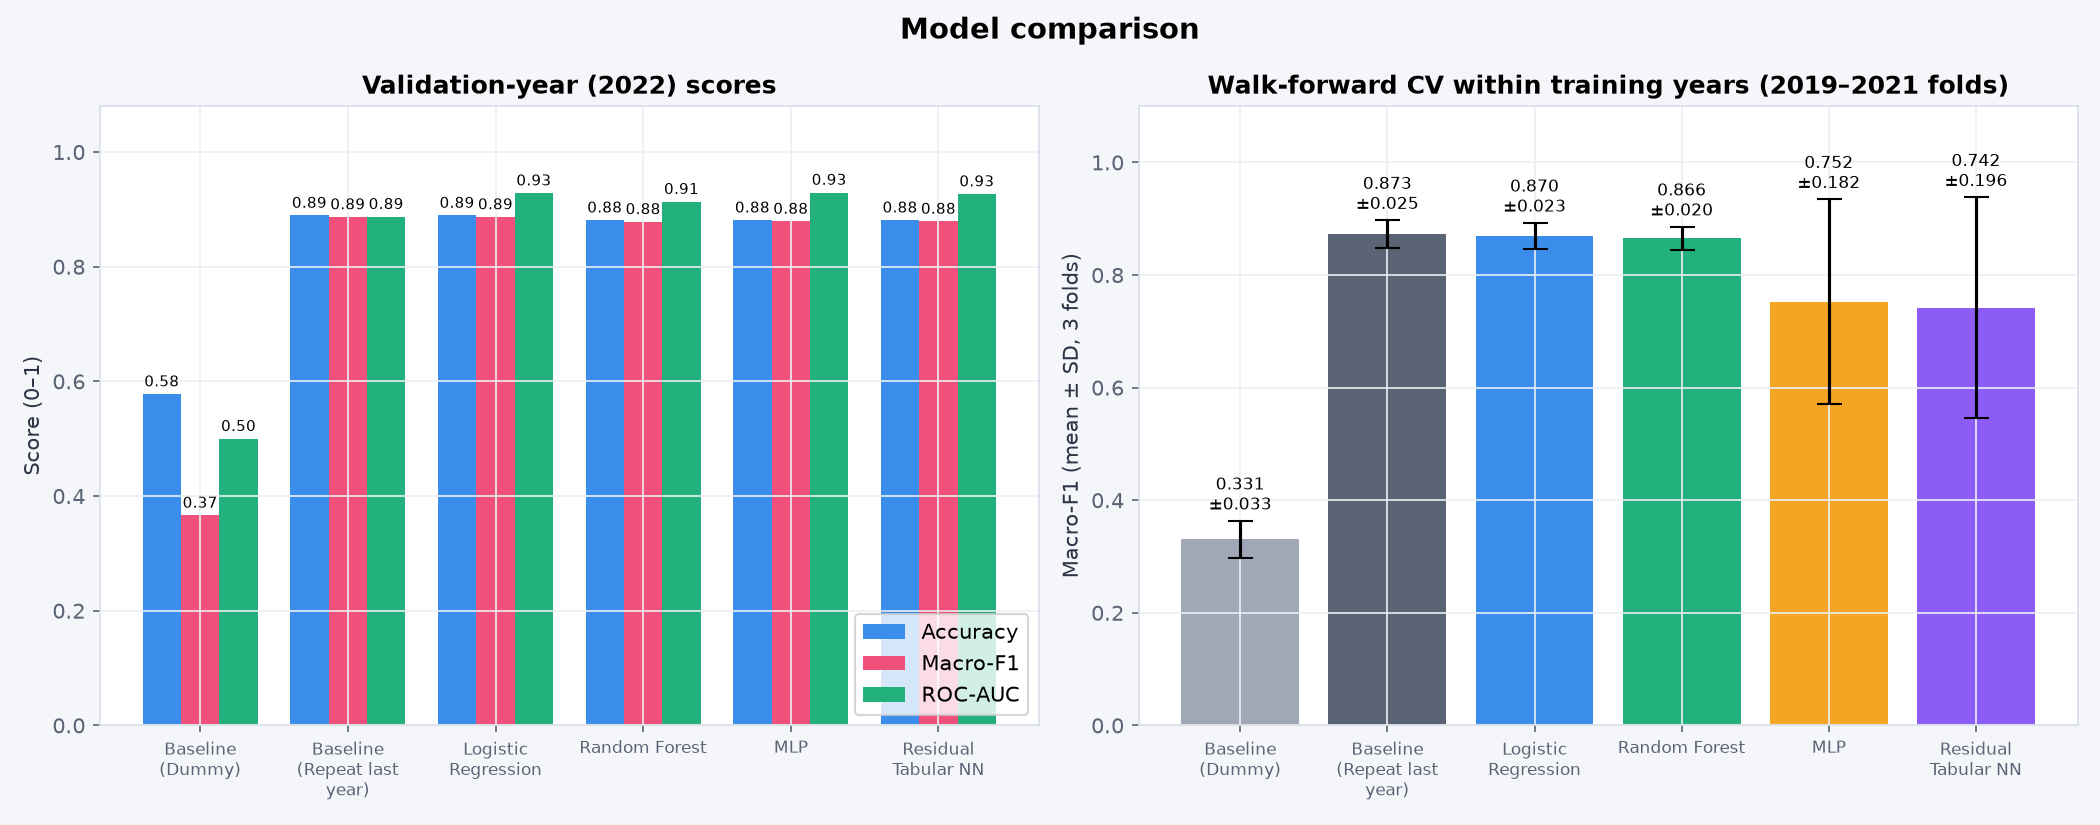

Provisional champion (validation macro-F1, ties broken by ROC-AUC): Logistic Regression


In [6]:
cv = pd.read_csv(RESULTS / "q4_cv_walk_forward.csv").set_index("model")
display(cv)
show("q4_model_comparison.png", 900)
print("Provisional champion (validation macro-F1, ties broken by ROC-AUC):",
      json.loads((RESULTS / "dashboard_q4.json").read_text())["champion"])

## 4.4 Overfitting: train–validation gap, learning curves and neural training curves

,train_macro_f1,val_macro_f1,train_accuracy,val_accuracy,macro_f1_gap,accuracy_gap
model,,,,,,
Baseline (Dummy),0.346,0.366,0.529,0.578,-0.020,-0.048
Baseline (Repeat last year),0.865,0.887,0.865,0.889,-0.022,-0.024
Logistic Regression,0.865,0.887,0.865,0.889,-0.022,-0.024
Random Forest,1.000,0.878,1.000,0.881,0.122,0.119
MLP,0.869,0.879,0.869,0.881,-0.010,-0.012
Residual Tabular NN,0.868,0.879,0.868,0.881,-0.011,-0.013


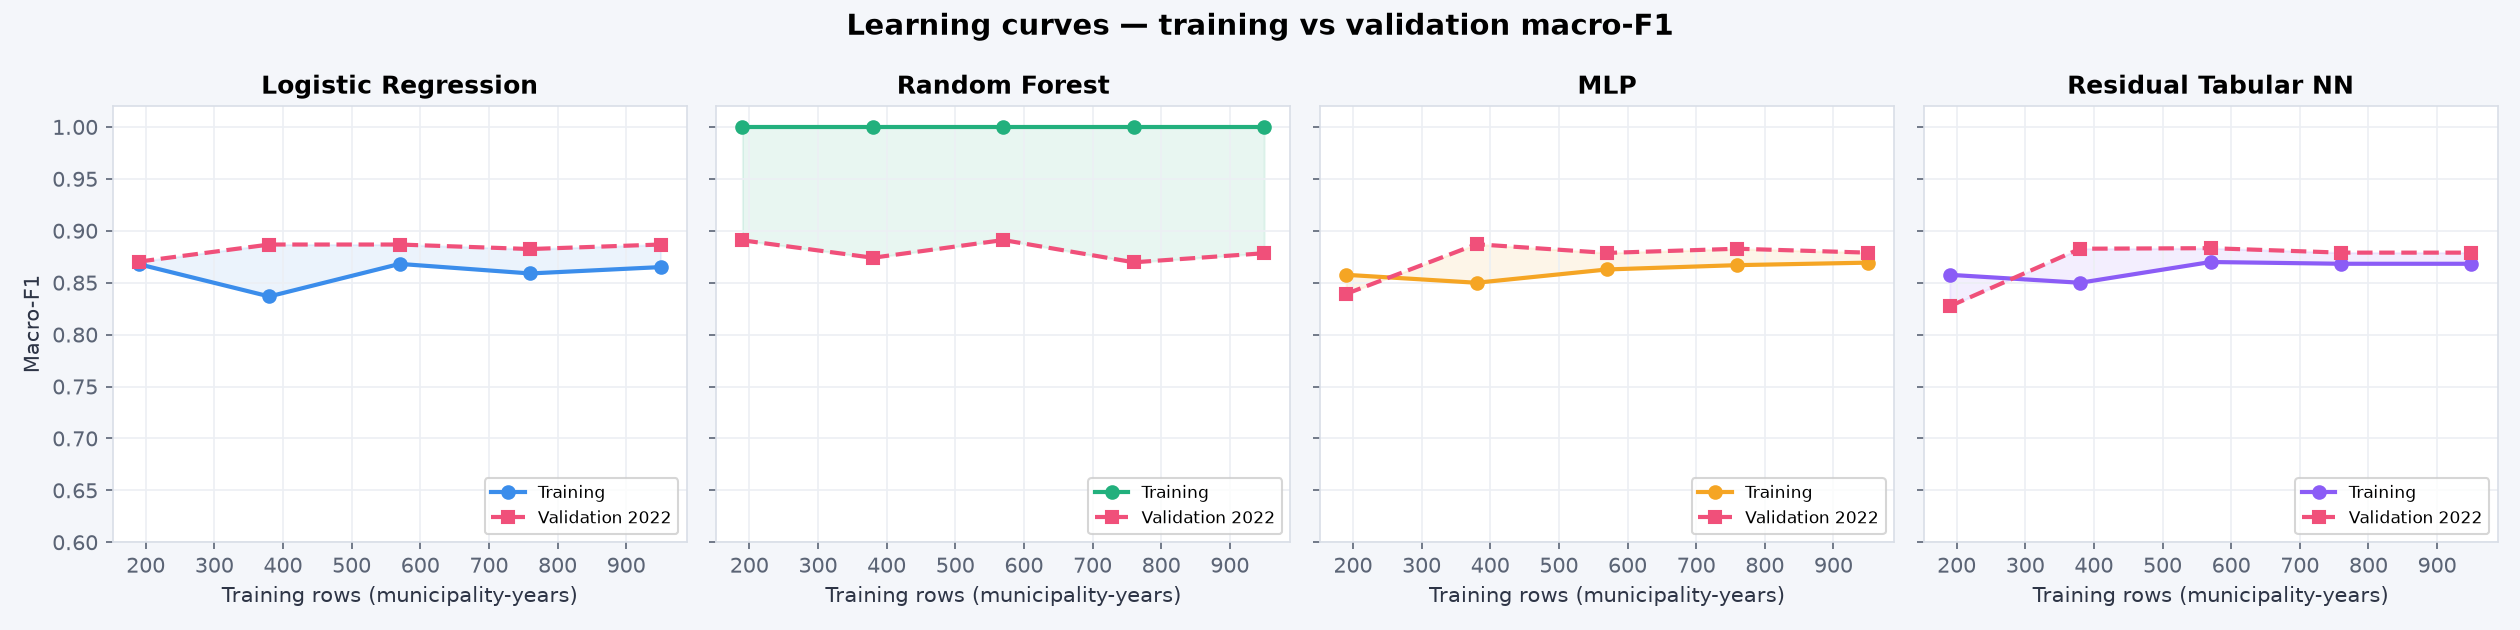

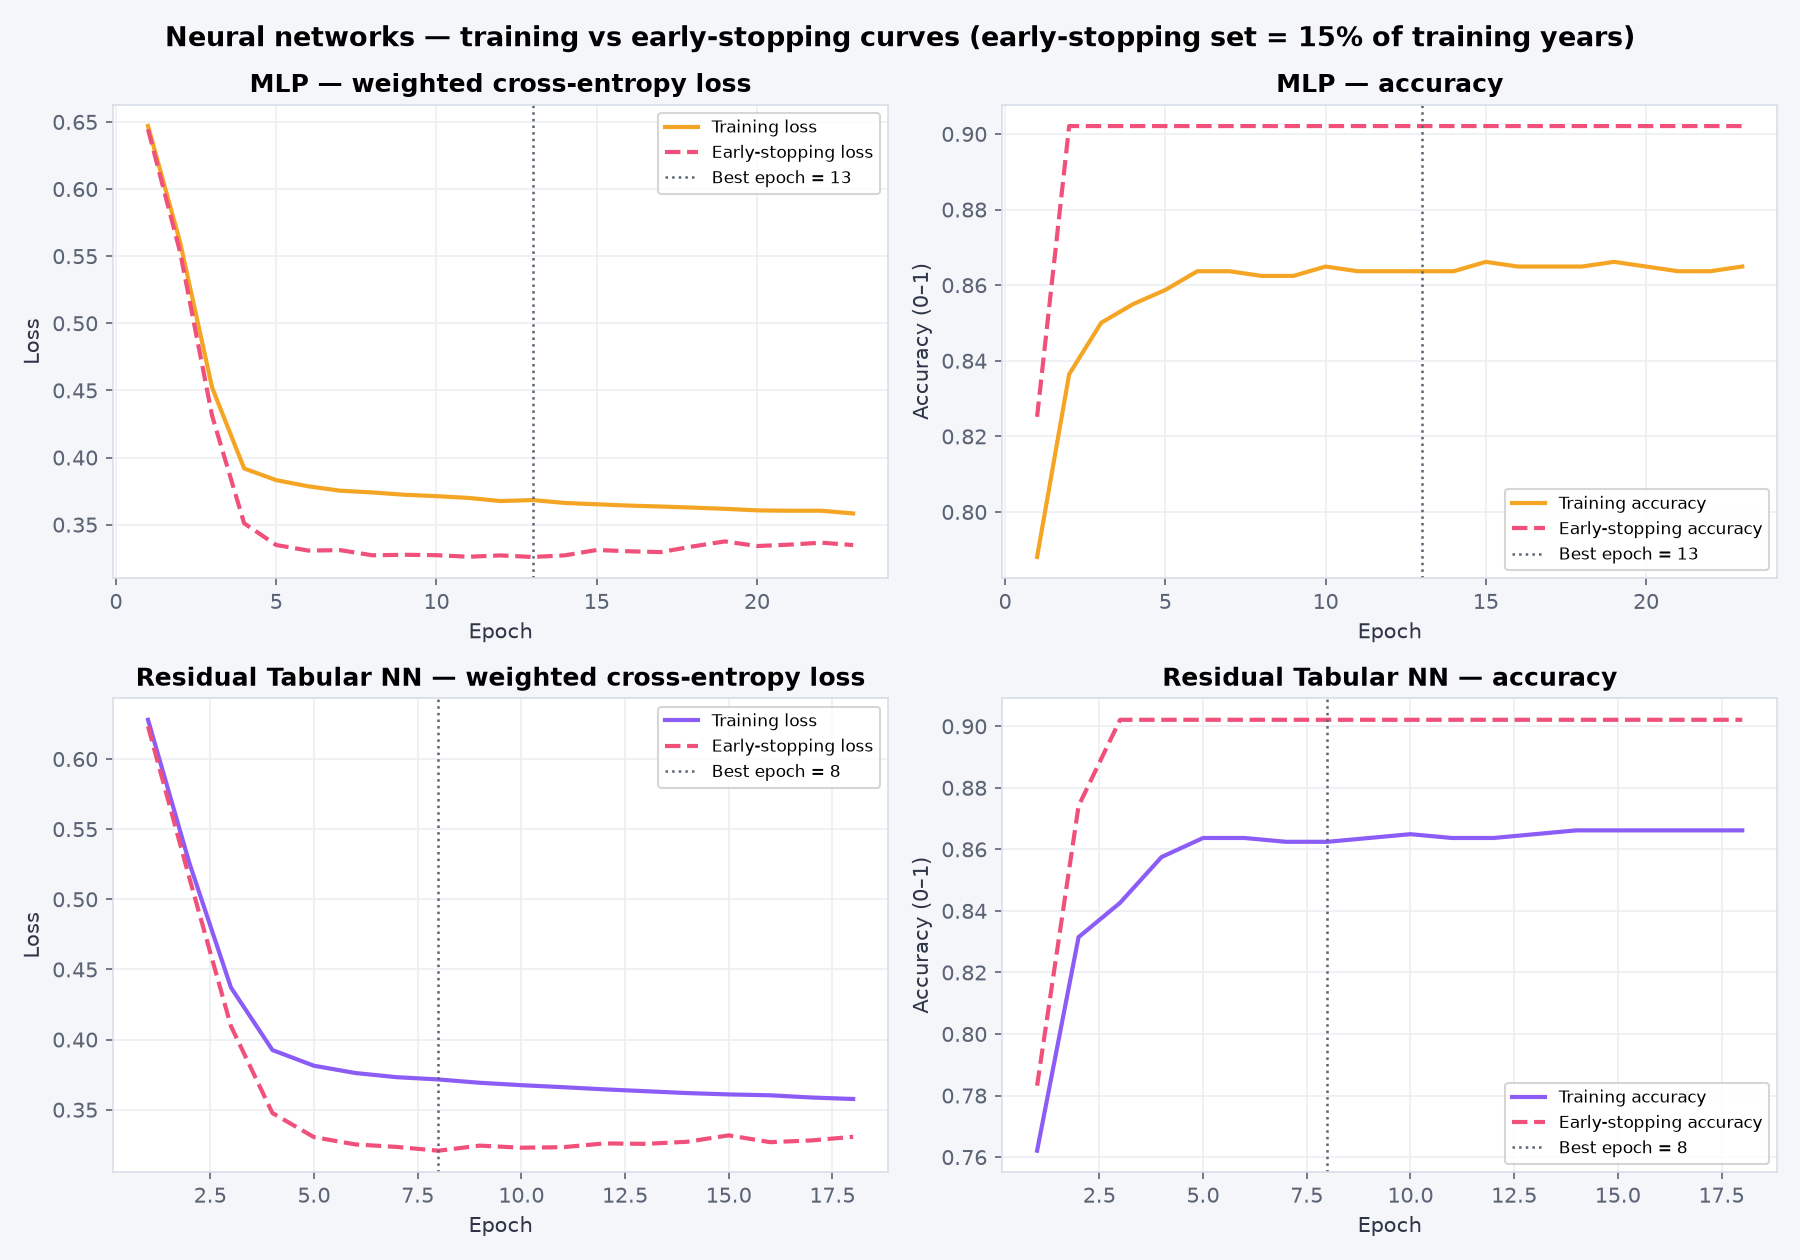

In [7]:
display(pd.read_csv(RESULTS / "q4_overfitting_gap.csv").set_index("model"))
show("q4_learning_curves.png", 900)
show("q4_neural_training_curves.png", 800)